# Лабораторна робота № 1

## Вхідний аналіз набору даних

**Дисципліна:** Інтелектуальний аналіз та візуалізація даних (СК26)
**Тривалість:** 2 год аудиторно + 3 год самостійної роботи · **Максимальна оцінка:** 4 бали

---

### Мета роботи

Пригадати роботу в Jupyter Notebook, бібліотеці `pandas` та побудову графіків —
і зробити це не на навчальному прикладі, а на реальному файлі, який ніхто не готував
спеціально для вас.

Ця робота виконується **до першої лекції**. Нічого нового знати не потрібно: усе,
що знадобиться, ви вже проходили в попередніх курсах. Усі поняття, яких ви тут
торкнетеся мимохідь, отримають назви й пояснення на лекціях 3 і 4.

### Дані

Файл `20171129_FINAL_FINAL.xlsx`, аркуш `Sheet1` — спостереження космічної погоди
за 28 серпня — 22 вересня 2017 року, зібрані з трьох різних джерел.

Файл видається **як є**, рівно в тому вигляді, у якому його колись вивантажили.
Ніхто не приводив його до ладу, і саме в цьому сенс: справжні дані здебільшого
надходять саме такими.

### Що ви маєте зробити

| Етап | Зміст | Де |
|---|---|---|
| 1 | Розібратися, що взагалі лежить у файлі | аудиторно |
| 2 | Виділити три таблиці й привести їх до робочого вигляду | аудиторно |
| 3 | Скласти паспорт даних: що є, чого бракує, що виглядає дивно | аудиторно |
| 4 | Об'єднати три таблиці в одну | аудиторно |
| 5 | Побудувати п'ять графіків, кожен — відповідь на питання | аудиторно + самостійно |
| 6 | Порівняти два графіки одних і тих самих даних | самостійно |
| 7 | Записати три спостереження про дані | самостійно |
| 8 | Декларація про використання інструментів ШІ | самостійно |

### Що здається

1. Цей файл `.ipynb` із заповненими розв'язками. **Ноутбук має виконуватися згори
   донизу на чистому ядрі** (Kernel → Restart & Run All) без помилок — це перевіряється
   першою дією на захисті.
2. Файл `master_hourly.csv` — об'єднана таблиця з етапу 4.
3. Експорт ноутбука у HTML або PDF.
4. Заповнена декларація (етап 8). Без неї фінальна самоперевірка не проходить.

### Критерії оцінювання

| Бали | Що досягнуто |
|---|---|
| 0 | Дані не опрацьовано, графіки не побудовано або побудовано з грубими помилками |
| 1 | Таблиці прочитано й кілька графіків побудовано, але типи графіків не відповідають даним, дивних значень не помічено |
| 2 | Таблиці розібрано й об'єднано, графіки коректні та підписані, але висновків під ними немає або вони формальні |
| 4 | Усе вище виконано, знайдено й пояснено дивні значення, під кожним графіком є змістовний висновок про дані |

**Головне про оцінку:** бали ставляться не за наявність графіка, а за речення під ним.
Код, який нічого не пояснює, коштує двох балів з чотирьох.

---
## Нагадування про Jupyter

Якщо давно не працювали — три речі, які знадобляться сьогодні:

* `Shift+Enter` виконує клітинку, `Esc` `A` / `Esc` `B` додає клітинку вище / нижче,
  `Esc` `M` перетворює клітинку на текстову (Markdown), `Esc` `Y` — назад на код.
* **Порядок виконання має значення.** Якщо ви правили клітинки в довільному порядку,
  результат може залежати від історії запусків. Перед здачею обов'язково
  **Kernel → Restart & Run All** — так ви побачите ноутбук очима викладача.
* Текстові клітинки — не прикраса. Висновки пишуться в них, а не в коментарях до коду.

---
## Крок 0. Ваші дані та варіант

Заповніть три змінні й виконайте обидві клітинки. Друга надрукує **ваше
індивідуальне завдання** — воно відрізняється від завдання сусіда.

In [3]:
ПІБ = 'Бубельник Юрій Олегович'        # напр. 'Шевченко Тарас'
ГРУПА = 'ШІ-31'      # напр. 'КН-31'
ВАРІАНТ = 2     # ваш номер за списком групи

assert ПІБ and ГРУПА and ВАРІАНТ, 'Заповніть ПІБ, ГРУПУ та ВАРІАНТ'

In [4]:
# --- клітинку не редагувати: вона видає ваше персональне завдання ------------
ПОТОКИ = ['P>1', 'P>5', 'P>10', 'P>30', 'P>50', 'P>100', 'E>0.8', 'E>2.0']

ПАРИ = [('швидкість вітру', 'густина вітру'),
        ('швидкість вітру', 'потік P>10'),
        ('густина вітру', 'потік P>1'),
        ('радіопотік F10.7', 'потік P>10'),
        ('радіопотік F10.7', 'швидкість вітру'),
        ('потік E>0.8', 'потік P>10')]

АГРЕГАТИ = ['середнє', 'максимум', 'медіана', 'мінімум']

ПИТАННЯ = [
    'Скільки годин за все вікно ваш потік перевищував своє власне медіанне значення?',
    'У яку добу середнє значення вашого потоку було найбільшим? А найменшим?',
    'О котрій годині доби потік E>0.8 у середньому найбільший? Побудуйте графік середнього за годинами доби.',
    'Яка частка рядків об’єднаної таблиці має пропуск хоча б в одному стовпці?',
    'У який день радіопотік F10.7 був найбільшим і чи збігається цей день з піком вашого потоку?',
    'Порівняйте медіану вашого потоку за перший і за другий тиждень спостережень. У скільки разів вони відрізняються?',
    'Скільки годин поспіль тривала найдовша неперервна серія «активних» годин (група з етапу 4)?',
    'Який зі стовпців об’єднаної таблиці має найбільший розкид відносно власного середнього?',
    'Яку частку сумарного значення вашого потоку за все вікно дали 24 години навколо піку?',
    'Скільки різних діб потрапило у групу «активні» і скільки — у групу «дуже активні»?',
]

i = int(ВАРІАНТ)
завдання = {
    'ваш потік':                      ПОТОКИ[(i * 3 + 1) % 8],
    'ваша пара для графіка 3':        ' та '.join(ПАРИ[(i * 5 + 2) % 6]),
    'ваш агрегат для етапу 4':        АГРЕГАТИ[(i * 5 + 1) % 4],
    'ваше додаткове питання':         ПИТАННЯ[(i * 11 + 5) % 10],
}

print('ІНДИВІДУАЛЬНЕ ЗАВДАННЯ · %s, %s, варіант %d' % (ПІБ, ГРУПА, i))
print('=' * 78)
for k, v in завдання.items():
    print('%-28s %s' % (k + ':', v))

ІНДИВІДУАЛЬНЕ ЗАВДАННЯ · Бубельник Юрій Олегович, ШІ-31, варіант 2
ваш потік:                   E>2.0
ваша пара для графіка 3:     швидкість вітру та густина вітру
ваш агрегат для етапу 4:     мінімум
ваше додаткове питання:      Який зі стовпців об’єднаної таблиці має найбільший розкид відносно власного середнього?


Далі за текстом **«ваш потік»** означає стовпець, названий у першому рядку завдання.

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 40)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 9})

ФАЙЛ = '20171129_FINAL_FINAL.xlsx'

---
# Етап 1. Що взагалі лежить у файлі

Перше правило роботи з незнайомими даними: спершу подивитися, потім рахувати.

### Завдання 1.1
Спробуйте прочитати аркуш `Sheet1` звичайним способом — `pd.read_excel(ФАЙЛ)` —
і виведіть перші рядки та типи стовпців.

*Очікуваний результат: результат буде дивним. Подивіться на назви стовпців і на
те, які там типи даних. Поясніть у наступній клітинці, чому так вийшло.*

In [6]:
# ВАШ КОД
TRY = pd.read_excel(ФАЙЛ)

display(TRY.head())
display(TRY.dtypes)

,Unnamed: 0,ftp://ftp.swpc.noaa.gov/pub/lists/particle/,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,Unnamed: 10,Unnamed: 11,Unnamed: 12,Unnamed: 13,Unnamed: 14,Unnamed: 15,Unnamed: 16,Unnamed: 17,Unnamed: 18,Unnamed: 19,Unnamed: 20,Unnamed: 21,Unnamed: 22,Unnamed: 23,Unnamed: 24,Unnamed: 25,http://umtof.umd.edu/pm/crn/,Unnamed: 27,Unnamed: 28,Unnamed: 29,Unnamed: 30,Unnamed: 31
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,:Data_list: 20170901_Gs_part_5m.txt,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,SOHO CELIAS Proton Monitor,NaN,NaN,NaN,NaN,NaN
2,NaN,:Created: 2017 Sep 02 0011 UTC,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Solar Wind Parameters for Carrington Rotation ...,NaN,NaN,NaN,NaN,NaN
3,NaN,"# Prepared by the U.S. Dept. of Commerce, NOAA...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Proton speed [km/sec],NaN,NaN,NaN,NaN,NaN
4,NaN,# Please send comments and suggestions to SWPC...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Proton density [protons per cubic centimeter],NaN,NaN,NaN,NaN,NaN


Unnamed: 0                                     float64
ftp://ftp.swpc.noaa.gov/pub/lists/particle/     object
Unnamed: 2                                      object
Unnamed: 3                                      object
Unnamed: 4                                      object
Unnamed: 5                                      object
Unnamed: 6                                      object
Unnamed: 7                                      object
Unnamed: 8                                      object
Unnamed: 9                                      object
Unnamed: 10                                     object
Unnamed: 11                                     object
Unnamed: 12                                     object
Unnamed: 13                                     object
Unnamed: 14                                     object
Unnamed: 15                                    float64
Unnamed: 16                                     object
Unnamed: 17                                     object
Unnamed: 1

**Відповідь 1.1:** *(чому звичайне читання дало саме такий результат)*

Звичайне читання дало такий результат, бо pd.read_excel(ФАЙЛ) автоматично сприймає перший рядок аркуша як заголовки стовпців. Але у цьому Excel-файлі на початку розміщені службові рядки та посилання на джерела даних, а не нормальний заголовок таблиці. Тому pandas створив багато колонок типу Unnamed: ..., а типи даних вийшли змішаними.

### Завдання 1.2
Прочитайте аркуш ще раз, але **без заголовка**: `pd.read_excel(ФАЙЛ, header=None)`.
Виведіть його розмір і подивіться на перші 30 рядків.

In [7]:
# ВАШ КОД
RAW = pd.read_excel(ФАЙЛ, header=None)

print(RAW.shape)
display(RAW.head(30))

(7226, 32)


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31
0,NaN,ftp://ftp.swpc.noaa.gov/pub/lists/particle/,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,http://umtof.umd.edu/pm/crn/,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,:Data_list: 20170901_Gs_part_5m.txt,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,SOHO CELIAS Proton Monitor,NaN,NaN,NaN,NaN,NaN
3,NaN,:Created: 2017 Sep 02 0011 UTC,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Solar Wind Parameters for Carrington Rotation ...,NaN,NaN,NaN,NaN,NaN
4,NaN,"# Prepared by the U.S. Dept. of Commerce, NOAA...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Proton speed [km/sec],NaN,NaN,NaN,NaN,NaN
5,NaN,# Please send comments and suggestions to SWPC...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Proton density [protons per cubic centimeter],NaN,NaN,NaN,NaN,NaN
6,NaN,#,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,NaN,# Label: P > 1 = Particles at >1 Mev,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"Measurement time (Year, Month, Day of Month, D...",NaN,NaN,NaN,NaN,NaN
8,NaN,# Label: P > 5 = Particles at >5 Mev,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,NaN,# Label: P >10 = Particles at >10 Mev,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Завдання 1.3
Для кожного стовпця порахуйте, скільки в ньому заповнених клітинок
(`RAW.notna().sum()`), і виведіть результат.

*Очікуваний результат: 32 числа. Серед них будуть нулі та згустки великих значень.
За цими згустками видно, що в аркуші **не одна таблиця, а кілька**, вставлені поруч.*

**Питання:** скільки таблиць в аркуші і які стовпці займає кожна?

In [8]:
# ВАШ КОД
filled = RAW.notna().sum()

display(filled)

0        0
1     7223
2     7202
3     7202
4     7202
5     7203
6     7203
7     7198
8     7198
9     7198
10    7198
11    7198
12    7198
13    7198
14    7198
15       0
16      32
17      26
18      26
19      26
20       0
21       0
22       0
23       0
24     601
25     601
26     608
27     602
28     602
29     602
30     602
31     602
dtype: int64

**Відповідь 1.3:** *(скільки таблиць і які стовпці кожна займає)*

В аркуші є три таблиці. Перша займає стовпці 1-14, друга займає стовпці 16-19, третя займає стовпці 24-31. Стовпці 0, 15, 20, 21, 22, 23 порожні або слугують розділювачами між таблицями.

### Завдання 1.4
Над кожною таблицею є кілька текстових рядків — це службовий опис від тих, хто дані
збирав. Виведіть їх і випишіть для кожної таблиці **джерело даних та одиниці
вимірювання**.

*Це найкорисніші п'ять хвилин роботи: жодної з цих відомостей у самій таблиці немає,
і без них ви не знатимете, у чому вимірюєте.*

In [9]:
# ВАШ КОД
display(RAW.iloc[:23, 1:15])

display(RAW.iloc[13:27, 16:20])

display(RAW.iloc[:8, 26:32])


,1,2,3,4,5,6,7,8,9,10,11,12,13,14
0,ftp://ftp.swpc.noaa.gov/pub/lists/particle/,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,:Data_list: 20170901_Gs_part_5m.txt,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,:Created: 2017 Sep 02 0011 UTC,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,"# Prepared by the U.S. Dept. of Commerce, NOAA...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,# Please send comments and suggestions to SWPC...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,#,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,# Label: P > 1 = Particles at >1 Mev,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,# Label: P > 5 = Particles at >5 Mev,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,# Label: P >10 = Particles at >10 Mev,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,16,17,18,19
13,ftp://ftp.swpc.noaa.gov/pub/indices/old_indice...,NaN,NaN,NaN
14,NaN,NaN,NaN,NaN
15,Product: Daily Solar Data quar_DSD.txt,NaN,NaN,NaN
16,:Issued: 0825 UT 04 Oct 2017,NaN,NaN,NaN
17,#,NaN,NaN,NaN
18,"# Prepared by the U.S. Dept. of Commerce, NOA...",NaN,NaN,NaN
19,# Please send comments and suggestions to SWP...,NaN,NaN,NaN
20,NaN,NaN,NaN,NaN
21,NaN,NaN,NaN,NaN
22,NaN,NaN,NaN,NaN


,26,27,28,29,30,31
0,http://umtof.umd.edu/pm/crn/,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN
2,SOHO CELIAS Proton Monitor,NaN,NaN,NaN,NaN,NaN
3,Solar Wind Parameters for Carrington Rotation ...,NaN,NaN,NaN,NaN,NaN
4,Proton speed [km/sec],NaN,NaN,NaN,NaN,NaN
5,Proton density [protons per cubic centimeter],NaN,NaN,NaN,NaN,NaN
6,NaN,NaN,NaN,NaN,NaN,NaN
7,"Measurement time (Year, Month, Day of Month, D...",NaN,NaN,NaN,NaN,NaN


**Відповідь 1.4:**

| Таблиця | Джерело | Одиниці вимірювання |
|---|---|---|
| A | NOAA Space Weather Prediction Center, GOES-15, `ftp://ftp.swpc.noaa.gov/pub/lists/particle/` | Протони: `Protons/cm2-s-sr`; електрони: `Electrons/cm2-s-sr`. Потоки для енергій `P>1`, `P>5`, `P>10`, `P>30`, `P>50`, `P>100`, `E>0.8`, `E>2.0`, `E>4.0` MeV |
| B | NOAA Space Weather Prediction Center, `ftp://ftp.swpc.noaa.gov/pub/indices/old_indices/2017Q3_DSD.txt` | Сонячний радіопотік `Radio Flux 10.7` |
| C | SOHO CELIAS Proton Monitor, `http://umtof.umd.edu/pm/crn/` | Швидкість протонів: `km/sec`; густина протонів: `protons per cubic centimeter` |

---
# Етап 2. Три таблиці в робочому вигляді

У файлі три таблиці. Ось що в них лежить — решту ви вже знайшли самі:

| Таблиця | Стовпці аркуша | Що це | Один рядок = |
|---|---|---|---|
| A | B–O | вимірювання із супутника GOES-15: потоки частинок різної енергії | 5 хвилин |
| B | Q–T | добовий показник сонячної активності F10.7 | доба |
| C | Y–AF | швидкість і густина сонячного вітру | година |

### Завдання 2.1
Виділіть кожну таблицю в окремий `DataFrame` — назвіть їх `A`, `B` і `C`.
Дайте стовпцям осмислені назви й перетворіть значення на числа
(`pd.to_numeric(..., errors='coerce')` стане в пригоді).

In [10]:
# ВАШ КОД
A = RAW.iloc[26:, 1:15].copy()
A.columns = [
    'year', 'month', 'day', 'hhmm',
    'mjd', 'seconds_of_day',
    'p_gt_1', 'p_gt_5', 'p_gt_10', 'p_gt_30', 'p_gt_50', 'p_gt_100',
    'e_gt_0_8', 'e_gt_2_0'
]
A = A.apply(pd.to_numeric, errors='coerce').reset_index(drop=True)


B = RAW.iloc[27:52, 16:20].copy()
B.columns = ['year', 'month', 'day', 'f10_7']
B = B.apply(pd.to_numeric, errors='coerce').reset_index(drop=True)


C = RAW.iloc[27:628, 24:32].copy()
C.columns = [
    'hour_index_1', 'hour_index_2',
    'year', 'month', 'day', 'hour',
    'wind_speed', 'wind_density'
]
C = C.apply(pd.to_numeric, errors='coerce').reset_index(drop=True)

display(A.head())
display(B.head())
display(C.head())

print('A:', A.shape)
print('B:', B.shape)
print('C:', C.shape)


,year,month,day,hhmm,mjd,seconds_of_day,p_gt_1,p_gt_5,p_gt_10,p_gt_30,p_gt_50,p_gt_100,e_gt_0_8,e_gt_2_0
0,2017,8,28,0,57993,0,12.00,0.260,0.180,0.1140,0.1040,0.0793,23600.0,1180.0
1,2017,8,28,5,57993,300,19.40,0.690,0.314,0.1120,0.0612,0.0251,23100.0,1160.0
2,2017,8,28,10,57993,600,8.48,0.168,0.130,0.0717,0.0614,0.0304,22200.0,1090.0
3,2017,8,28,15,57993,900,15.40,0.566,0.198,0.0926,0.0568,0.0251,20400.0,997.0
4,2017,8,28,20,57993,1200,6.41,0.156,0.118,0.0597,0.0494,0.0251,18500.0,875.0


,year,month,day,f10_7
0,2017,8,28,82
1,2017,8,29,84
2,2017,8,30,87
3,2017,8,31,92
4,2017,9,1,93


,hour_index_1,hour_index_2,year,month,day,hour,wind_speed,wind_density
0,0.0,0.0,17,8,28,0,285,3.0
1,1.0,1.0,17,8,28,1,305,3.4
2,2.0,2.0,17,8,28,2,309,1.7
3,3.0,3.0,17,8,28,3,304,2.0
4,4.0,4.0,17,8,28,4,302,2.3


A: (7200, 14)
B: (25, 4)
C: (601, 8)


### Завдання 2.2
У кожній таблиці дата й час записані **по-різному** й розкидані по кількох стовпцях.
Зберіть для кожної таблиці один стовпець `ts` типу `datetime`.

Після цього обов'язково виведіть для кожної таблиці найранішу й найпізнішу дату.

*Очікуваний результат: усі три таблиці мають лежати в межах серпня–вересня 2017 року.
Якщо у вас вийшов інший рік — придивіться, як записано рік у тій таблиці, і виправте.*

In [11]:
# ВАШ КОД
A['hour'] = (A['hhmm'] // 100).astype(int)
A['minute'] = (A['hhmm'] % 100).astype(int)

A['ts'] = pd.to_datetime(dict(
    year=A['year'],
    month=A['month'],
    day=A['day'],
    hour=A['hour'],
    minute=A['minute']
))


B['ts'] = pd.to_datetime(dict(
    year=B['year'],
    month=B['month'],
    day=B['day']
))


C['ts'] = pd.to_datetime(dict(
    year=C['year'] + 2000,
    month=C['month'],
    day=C['day'],
    hour=C['hour']
))


print('A:', A['ts'].min(), '—', A['ts'].max())
print('B:', B['ts'].min(), '—', B['ts'].max())
print('C:', C['ts'].min(), '—', C['ts'].max())

A: 2017-08-28 00:00:00 — 2017-09-21 23:55:00
B: 2017-08-28 00:00:00 — 2017-09-21 00:00:00
C: 2017-08-28 00:00:00 — 2017-09-22 00:00:00


**Самоперевірка етапу 2.** Клітинка має виконатися без помилок.

In [12]:
assert len(A) == 7200, 'у таблиці A має бути 7200 рядків, а є %d' % len(A)
assert len(B) == 25,   'у таблиці B має бути 25 рядків, а є %d' % len(B)
assert len(C) == 601,  'у таблиці C має бути 601 рядок, а є %d' % len(C)
for назва, т in [('A', A), ('B', B), ('C', C)]:
    рік = pd.to_datetime(т['ts']).dt.year
    assert рік.min() == 2017 and рік.max() == 2017, 'у таблиці %s рік не 2017 — перевірте збирання дати' % назва
print('Етап 2 пройдено')

Етап 2 пройдено


---
# Етап 3. Паспорт даних

### Завдання 3.1
Для кожної таблиці виведіть: розмір, типи стовпців, кількість пропусків у кожному
стовпці, кількість повних дублікатів рядків і описові статистики (`describe()`).

In [13]:
# ВАШ КОД
for name, df in [('A', A), ('B', B), ('C', C)]:
    print('=' * 60)
    print(f'Table {name}')
    print('=' * 60)

    print('Shape:')
    print(df.shape)

    print('\nColumn types:')
    print(df.dtypes)

    print('\nMissing values in each column:')
    print(df.isna().sum())

    print('\nNumber of full duplicate rows:')
    print(df.duplicated().sum())

    print('\nDescriptive statistics:')
    display(df.describe())

    print('\n')

Table A
Shape:
(7200, 17)

Column types:
year                       int64
month                      int64
day                        int64
hhmm                       int64
mjd                        int64
seconds_of_day             int64
p_gt_1                   float64
p_gt_5                   float64
p_gt_10                  float64
p_gt_30                  float64
p_gt_50                  float64
p_gt_100                 float64
e_gt_0_8                 float64
e_gt_2_0                 float64
hour                       int64
minute                     int64
ts                datetime64[us]
dtype: object

Missing values in each column:
year              0
month             0
day               0
hhmm              0
mjd               0
seconds_of_day    0
p_gt_1            3
p_gt_5            3
p_gt_10           3
p_gt_30           3
p_gt_50           3
p_gt_100          3
e_gt_0_8          3
e_gt_2_0          3
hour              0
minute            0
ts                0
dtype: int64

,year,month,day,hhmm,mjd,seconds_of_day,p_gt_1,p_gt_5,p_gt_10,p_gt_30,p_gt_50,p_gt_100,e_gt_0_8,e_gt_2_0,hour,minute,ts
count,7200.0,7200.000000,7200.000000,7200.000000,7200.000000,7200.000000,7197.000000,7197.000000,7197.000000,7197.000000,7197.000000,7197.00000,7197.000000,7197.000000,7200.000000,7200.000000,7200
mean,2017.0,8.840000,13.960000,1177.500000,58005.000000,43050.000000,689.325064,156.626057,76.474020,18.838604,7.446840,1.65929,81862.741801,11401.502123,11.500000,27.500000,2017-09-09 11:57:30
min,2017.0,8.000000,1.000000,0.000000,57993.000000,0.000000,0.429000,0.151000,0.117000,0.057600,0.045500,0.02240,4.300000,0.133000,0.000000,0.000000,2017-08-28 00:00:00
25%,2017.0,9.000000,7.000000,588.750000,57999.000000,21525.000000,11.700000,0.279000,0.186000,0.098400,0.059700,0.02630,22200.000000,552.000000,5.750000,13.750000,2017-09-03 05:58:45
50%,2017.0,9.000000,13.000000,1177.500000,58005.000000,43050.000000,55.400000,0.632000,0.376000,0.146000,0.086600,0.03630,68600.000000,4290.000000,11.500000,27.500000,2017-09-09 11:57:30
75%,2017.0,9.000000,19.000000,1766.250000,58011.000000,64575.000000,560.000000,107.000000,35.800000,0.990000,0.249000,0.06700,143000.000000,14100.000000,17.250000,41.250000,2017-09-15 17:56:15
max,2017.0,9.000000,31.000000,2355.000000,58017.000000,86100.000000,32500.000000,2890.000000,1330.000000,399.000000,191.000000,61.50000,259000.000000,110000.000000,23.000000,55.000000,2017-09-21 23:55:00
std,0.0,0.366632,8.775483,692.481902,7.211603,24943.113498,1625.968447,390.921861,222.362627,67.265595,28.620524,7.15889,65728.005824,16920.617446,6.922667,17.261461,NaN




Table B
Shape:
(25, 5)

Column types:
year              int64
month             int64
day               int64
f10_7             int64
ts       datetime64[us]
dtype: object

Missing values in each column:
year     0
month    0
day      0
f10_7    0
ts       0
dtype: int64

Number of full duplicate rows:
0

Descriptive statistics:


,year,month,day,f10_7,ts
count,25.0,25.000000,25.000000,25.000000,25
mean,2017.0,8.840000,13.960000,92.680000,2017-09-09 00:00:00
min,2017.0,8.000000,1.000000,71.000000,2017-08-28 00:00:00
25%,2017.0,9.000000,7.000000,74.000000,2017-09-03 00:00:00
50%,2017.0,9.000000,13.000000,84.000000,2017-09-09 00:00:00
75%,2017.0,9.000000,19.000000,107.000000,2017-09-15 00:00:00
max,2017.0,9.000000,31.000000,140.000000,2017-09-21 00:00:00
std,0.0,0.374166,8.955817,22.206831,NaN




Table C
Shape:
(601, 9)

Column types:
hour_index_1           float64
hour_index_2           float64
year                     int64
month                    int64
day                      int64
hour                     int64
wind_speed               int64
wind_density           float64
ts              datetime64[us]
dtype: object

Missing values in each column:
hour_index_1    0
hour_index_2    0
year            0
month           0
day             0
hour            0
wind_speed      0
wind_density    0
ts              0
dtype: int64

Number of full duplicate rows:
0

Descriptive statistics:


,hour_index_1,hour_index_2,year,month,day,hour,wind_speed,wind_density,ts
count,601.000000,601.000000,601.0,601.000000,601.000000,601.000000,601.000000,601.000000,601
mean,11.480865,11.480865,17.0,8.840266,13.973378,11.480865,506.547421,2.907654,2017-09-09 12:00:00
min,0.000000,0.000000,17.0,8.000000,1.000000,0.000000,-1.000000,-1.000000,2017-08-28 00:00:00
25%,5.000000,5.000000,17.0,9.000000,7.000000,5.000000,447.000000,1.800000,2017-09-03 06:00:00
50%,11.000000,11.000000,17.0,9.000000,13.000000,11.000000,517.000000,2.400000,2017-09-09 12:00:00
75%,17.000000,17.000000,17.0,9.000000,19.000000,17.000000,584.000000,3.400000,2017-09-15 18:00:00
max,23.000000,23.000000,17.0,9.000000,31.000000,23.000000,806.000000,31.700000,2017-09-22 00:00:00
std,6.938063,6.938063,0.0,0.366664,8.781000,6.938063,125.073291,2.637873,NaN


### Завдання 3.2 — дивні значення
Подивіться на рядок `min` у таблиці `describe()` для таблиці C.

Швидкість і густина — фізичні величини, які **не можуть бути від'ємними**.
Знайдіть від'ємні значення, порахуйте, скільки їх, і поверніться до службового опису
з завдання 1.4: там написано, що вони означають.

Замініть ці значення на `NaN` і покажіть, як після цього змінилися середнє й мінімум.

*Очікуваний результат: два числа «до» і «після» для кожного зі стовпців.*

In [14]:
# ВАШ КОД
cols = ['wind_speed', 'wind_density']

print('Negative values count:')
print((C[cols] < 0).sum())

print('\nRows with negative values:')
display(C.loc[(C[cols] < 0).any(axis=1), ['ts'] + cols])

before = C[cols].agg(['mean', 'min'])

C[cols] = C[cols].mask(C[cols] < 0)

after = C[cols].agg(['mean', 'min'])

print('Before cleaning:')
display(before)

print('After cleaning:')
display(after)

Negative values count:
wind_speed      8
wind_density    8
dtype: int64

Rows with negative values:


,ts,wind_speed,wind_density
175,2017-09-04 07:00:00,-1,-1.0
176,2017-09-04 08:00:00,-1,-1.0
177,2017-09-04 09:00:00,-1,-1.0
178,2017-09-04 10:00:00,-1,-1.0
179,2017-09-04 11:00:00,-1,-1.0
180,2017-09-04 12:00:00,-1,-1.0
181,2017-09-04 13:00:00,-1,-1.0
182,2017-09-04 14:00:00,-1,-1.0


Before cleaning:


,wind_speed,wind_density
mean,506.547421,2.907654
min,-1.000000,-1.000000


After cleaning:


,wind_speed,wind_density
mean,513.394604,2.960371
min,277.000000,0.100000


**Відповідь 3.2:** *(що це за значення, скільки їх, як вони спотворювали середнє)*

### Завдання 3.3 — питання на подумати
У таблиці A є стовпці, для яких `describe()` слухняно рахує середнє й стандартне
відхилення, хоча ці числа не мають жодного сенсу.

Знайдіть їх і поясніть своїми словами, чому середнє для них безглузде.

*Підказка: не кожне число в таблиці є результатом вимірювання.*

> Це питання не має однієї «правильної» відповіді з підручника — на нього ви
> відповідаєте з власного здорового глузду. Формальне пояснення буде на лекції 3.

In [15]:
# ВАШ КОД
service_cols = [
    'year', 'month', 'day', 'hhmm',
    'mjd', 'seconds_of_day', 'hour', 'minute'
]

print('Service and time-related columns:')
display(A[service_cols].agg(['mean', 'std']))

Service and time-related columns:


,year,month,day,hhmm,mjd,seconds_of_day,hour,minute
mean,2017.0,8.840000,13.960000,1177.500000,58005.000000,43050.000000,11.500000,27.500000
std,0.0,0.366632,8.775483,692.481902,7.211603,24943.113498,6.922667,17.261461


**Відповідь 3.3:** *(які це стовпці та чому середнє для них не має сенсу)*

Це стовпці year, month, day, hhmm, mjd, seconds_of_day, hour і minute. Вони містять числові позначення дати й часу, а не результати фізичних вимірювань. Тому Pandas може формально обчислити для них середнє та стандартне відхилення, але ці значення не описують сонячну активність і не мають корисного фізичного змісту. Наприклад, середній номер місяця або середнє значення hhmm нічого змістовного не означає.

---
# Етап 4. Об'єднання трьох таблиць в одну

Таблиці мають різний крок у часі: 5 хвилин, година і доба. Щоб працювати з ними
разом, потрібна спільна сітка. Беремо **годину**.

Кожна таблиця потребує своєї дії:

1. **A: 5 хвилин → година.** Кілька рядків згортаються в один — це `resample` + агрегація.
2. **C: уже година.** Просте з'єднання по спільному стовпцю `ts` — `merge`.
3. **B: доба → година.** Навпаки, одне значення розтягується на 24 години доби.

### Завдання 4.1
Зведіть таблицю A до погодинної сітки. Для кожного потоку порахуйте **два** числа
за годину: середнє і максимум.

In [16]:
# ВАШ КОД
flux_cols = [
    'p_gt_1', 'p_gt_5', 'p_gt_10',
    'p_gt_30', 'p_gt_50', 'p_gt_100',
    'e_gt_0_8', 'e_gt_2_0'
]

A_hourly = (
    A.set_index('ts')[flux_cols]
     .resample('1h')
     .agg(['mean', 'max'])
)

A_hourly.columns = [
    f'{column}_{statistic}'
    for column, statistic in A_hourly.columns
]

A_hourly = A_hourly.reset_index()

print('Shape:', A_hourly.shape)
display(A_hourly.head())

Shape: (600, 17)


,ts,p_gt_1_mean,p_gt_1_max,p_gt_5_mean,p_gt_5_max,p_gt_10_mean,p_gt_10_max,p_gt_30_mean,p_gt_30_max,p_gt_50_mean,p_gt_50_max,p_gt_100_mean,p_gt_100_max,e_gt_0_8_mean,e_gt_0_8_max,e_gt_2_0_mean,e_gt_2_0_max
0,2017-08-28 00:00:00,9.778333,19.40,0.324917,0.690,0.192917,0.314,0.098850,0.2240,0.077583,0.1780,0.040692,0.0793,20941.666667,23600.0,1011.583333,1180.0
1,2017-08-28 01:00:00,7.994167,13.60,0.291667,0.512,0.156583,0.259,0.072583,0.0919,0.058700,0.0798,0.029950,0.0471,18091.666667,20600.0,713.000000,907.0
2,2017-08-28 02:00:00,6.099167,10.80,0.283000,0.479,0.177667,0.321,0.084450,0.1210,0.069642,0.1110,0.035025,0.0595,14108.333333,15000.0,380.833333,475.0
3,2017-08-28 03:00:00,4.752500,7.76,0.236833,0.329,0.166333,0.244,0.087658,0.1800,0.068092,0.1390,0.035517,0.0818,12766.666667,13100.0,267.916667,284.0
4,2017-08-28 04:00:00,4.158333,6.62,0.334917,0.539,0.208333,0.309,0.084800,0.1530,0.072850,0.1420,0.039708,0.0694,11333.333333,12300.0,203.000000,234.0


### Завдання 4.2
У вашому завданні названо агрегат (`середнє`, `максимум`, `медіана` або `мінімум`).

Візьміть ваш потік за одну добу, порахуйте для нього по годинах ваш агрегат і ще один
на ваш вибір, і побудуйте обидві криві на одному графіку.

**Питання:** чим вони відрізняються і в якій ситуації різниця між ними стане суттєвою?

,min,mean
ts,,
2017-09-10 00:00:00,16100.0,16425.000000
2017-09-10 01:00:00,13400.0,14666.666667
2017-09-10 02:00:00,12300.0,12741.666667
2017-09-10 03:00:00,11500.0,12033.333333
2017-09-10 04:00:00,11500.0,11508.333333
2017-09-10 05:00:00,11300.0,11366.666667
2017-09-10 06:00:00,10400.0,11000.000000
2017-09-10 07:00:00,10300.0,10850.000000
2017-09-10 08:00:00,11300.0,11533.333333


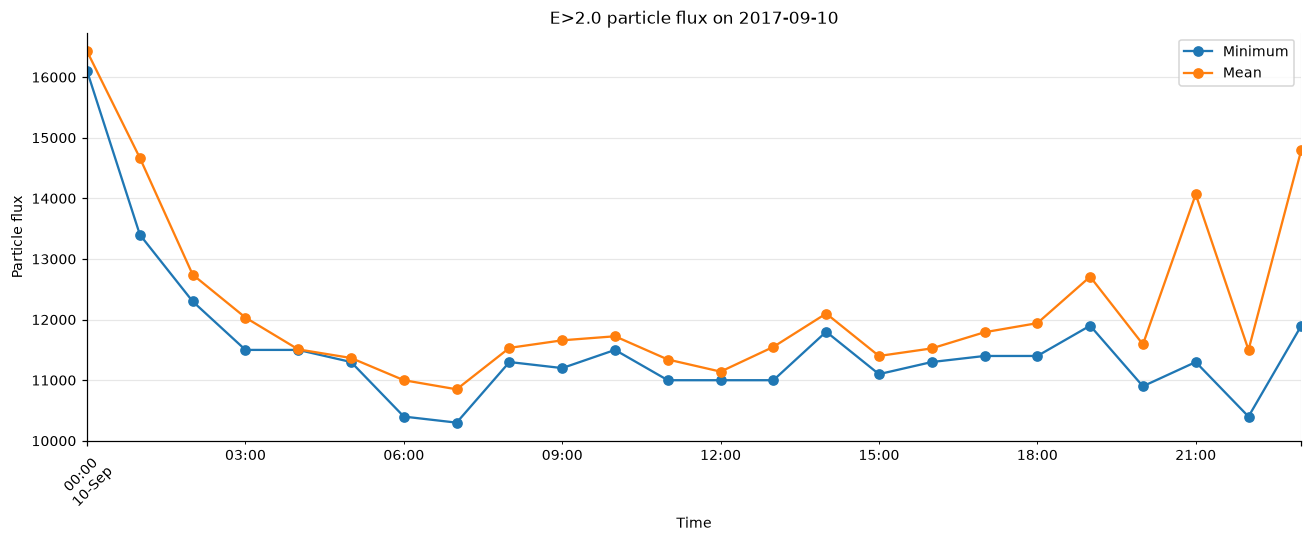

In [17]:
# ВАШ КОД
import matplotlib.pyplot as plt

day = '2017-09-10'
flow_col = 'e_gt_2_0'

hourly_comparison = (
    A.set_index('ts')
     .loc[day, flow_col]
     .resample('1h')
     .agg(['min', 'mean'])
)

display(hourly_comparison)

hourly_comparison.plot(
    figsize=(12, 5),
    marker='o'
)

plt.title(f'E>2.0 particle flux on {day}')
plt.xlabel('Time')
plt.ylabel('Particle flux')
plt.grid(True, alpha=0.3)
plt.legend(['Minimum', 'Mean'])
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Відповідь 4.2:** *(чим відрізняються криві та коли це важливо)* 

Мінімум показує найменше значення потоку серед усіх
5-хвилинних спостережень протягом години, а середнє враховує всі значення
за цю годину. Різниця між кривими стає суттєвою, коли потік сильно змінюється
протягом години або містить короткі різкі сплески. Якщо значення стабільні,
мінімум і середнє будуть близькими.

### Завдання 4.3
Об'єднайте три таблиці в одну — назвіть її `M`. Виведіть її розмір і всі рядки,
у яких є хоча б один пропуск.

**Зверніть увагу:** таблиці закінчуються не в один і той самий момент. Тому результат
залежить від того, який тип об'єднання ви оберете (`how='inner'` чи `how='outer'`).
Спробуйте обидва, подивіться, чим відрізняється кількість рядків, і поясніть свій вибір.

In [18]:
# ВАШ КОД
hourly_index = pd.date_range(
    start=B['ts'].min(),
    end=B['ts'].max() + pd.Timedelta(hours=23),
    freq='1h'
)

B_hourly = (
    B.set_index('ts')[['f10_7']]
     .reindex(hourly_index)
     .ffill()
     .rename_axis('ts')
     .reset_index()
)

C_hourly = C[['ts', 'wind_speed', 'wind_density']].copy()

M_inner = (
    A_hourly
    .merge(C_hourly, on='ts', how='inner')
    .merge(B_hourly, on='ts', how='inner')
)

M_outer = (
    A_hourly
    .merge(C_hourly, on='ts', how='outer')
    .merge(B_hourly, on='ts', how='outer')
    .sort_values('ts')
    .reset_index(drop=True)
)

print('Inner shape:', M_inner.shape)
print('Outer shape:', M_outer.shape)

M = M_outer

print('M shape:', M.shape)

print('\nRows with at least one missing value:')
display(M[M.isna().any(axis=1)])


Inner shape: (600, 20)
Outer shape: (601, 20)
M shape: (601, 20)

Rows with at least one missing value:


,ts,p_gt_1_mean,p_gt_1_max,p_gt_5_mean,p_gt_5_max,p_gt_10_mean,p_gt_10_max,p_gt_30_mean,p_gt_30_max,p_gt_50_mean,p_gt_50_max,p_gt_100_mean,p_gt_100_max,e_gt_0_8_mean,e_gt_0_8_max,e_gt_2_0_mean,e_gt_2_0_max,wind_speed,wind_density,f10_7
175,2017-09-04 07:00:00,6.465833,10.10,0.262083,0.593,0.171500,0.294,0.085483,0.145,0.068558,0.134,0.031717,0.0523,90600.000000,100000.0,7410.833333,8950.0,NaN,NaN,140.0
176,2017-09-04 08:00:00,4.010833,5.08,0.256000,0.432,0.195833,0.336,0.086625,0.145,0.070033,0.134,0.036492,0.0546,73483.333333,79300.0,5048.333333,5850.0,NaN,NaN,140.0
177,2017-09-04 09:00:00,3.268333,4.42,0.303417,0.518,0.220333,0.302,0.105925,0.162,0.081975,0.134,0.046483,0.0765,60475.000000,68500.0,3715.833333,4480.0,NaN,NaN,140.0
178,2017-09-04 10:00:00,3.179167,4.74,0.252167,0.372,0.181833,0.280,0.101900,0.150,0.081675,0.120,0.054125,0.0894,64383.333333,68400.0,4122.500000,4710.0,NaN,NaN,140.0
179,2017-09-04 11:00:00,5.274167,7.98,0.295083,0.657,0.186917,0.276,0.089525,0.166,0.063983,0.110,0.033633,0.0684,79933.333333,88200.0,6345.833333,7430.0,NaN,NaN,140.0
180,2017-09-04 12:00:00,2.965000,4.85,0.217750,0.428,0.153500,0.239,0.089217,0.179,0.071217,0.144,0.037233,0.0679,80516.666667,88700.0,6080.000000,7420.0,NaN,NaN,140.0
181,2017-09-04 13:00:00,3.061667,3.86,0.275833,0.551,0.192833,0.329,0.104542,0.170,0.083783,0.159,0.041342,0.0611,76733.333333,85900.0,6015.833333,7540.0,NaN,NaN,140.0
182,2017-09-04 14:00:00,7.279167,10.80,0.231333,0.409,0.170583,0.313,0.086508,0.178,0.070667,0.166,0.037375,0.0888,83025.000000,90200.0,8552.500000,10500.0,NaN,NaN,140.0
600,2017-09-22 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,381.0,1.0,NaN


**Відповідь 4.3:** *(який тип об'єднання обрано, скільки рядків дає кожен і чому)*

Об'єднання `inner` залишає лише ті години, які присутні
одночасно в усіх трьох таблицях. Об'єднання `outer` зберігає всі години,
навіть якщо для деяких із них немає даних в одній або двох таблицях.

Я обрав `outer`, оскільки так не втрачаються наявні спостереження. Пропуски
в отриманій таблиці показують години, для яких дані відсутні, зокрема через
те, що початкові таблиці закінчуються в різний час.

### Завдання 4.4 — поділ на групи
Щоб далі було що з чим порівнювати, поділіть години на три групи за значенням
**максимуму потоку P>10 за годину**:

| Група | Умова |
|---|---|
| `тиха` | менше 10 |
| `активна` | від 10 до 1000 |
| `дуже активна` | 1000 і більше |

Додайте до `M` стовпець `група` і виведіть, скільки годин потрапило в кожну.

> Це не вигадані числа: саме такі пороги використовує метеослужба космічної погоди
> NOAA. Чому вони саме такі — питання не сьогоднішньої роботи.

In [19]:
# ВАШ КОД
M['група'] = pd.cut(
    M['p_gt_10_max'],
    bins=[-float('inf'), 10, 1000, float('inf')],
    labels=['тиха', 'активна', 'дуже активна'],
    right=False
)

print('Number of hours in each group:')
print(M['група'].value_counts(sort=False, dropna=False))

Number of hours in each group:
група
тиха            411
активна         171
дуже активна     18
NaN               1
Name: count, dtype: int64


**Самоперевірка етапу 4.**

In [20]:
assert M is not None, 'таблиця M не побудована'
assert 'ts' in M.columns, 'у таблиці M потрібен стовпець ts'
assert 'група' in M.columns, 'у таблиці M потрібен стовпець «група»'
assert 590 <= len(M) <= 605, 'очікується близько 600 рядків, а є %d — перевірте об’єднання' % len(M)
print('Етап 4 пройдено:', len(M), 'рядків')

Етап 4 пройдено: 601 рядків


---
# Етап 5. П'ять графіків — п'ять питань

Графік будується як **відповідь на питання**, а не «щоб був».

**Вимоги до кожного графіка:**

* підписані обидві осі, з одиницями вимірювання;
* заголовок;
* під графіком, у текстовій клітинці, — **одне речення про дані**.
  Не «на графіку зображено потік протонів», а твердження на кшталт
  «більшість годин потік не перевищує 60, але кілька годин дають значення у сотні разів більші».

> Не кожне питання має відповідь «так, зв'язок є». Якщо на графіку нічого не видно —
> так і напишіть. Відсутність зв'язку — це теж результат, і чесно про неї написати
> важливіше, ніж підбирати ракурс, у якому «щось наче проглядається».

### Графік 1. Як розподілені значення вашого потоку?
Побудуйте гістограму вашого потоку (середнє за годину). Порахуйте окремо середнє
й медіану цього стовпця.

Якщо гістограма вийде нечитабельною — стовпчик біля нуля і порожньо далі — не
залишайте так. Спробуйте побудувати гістограму від логарифма значень
(`np.log10`) і подивіться, що зміниться.

**Питання:** чому середнє й медіана так сильно відрізняються?

Mean: 11397.05
Median: 4338.75


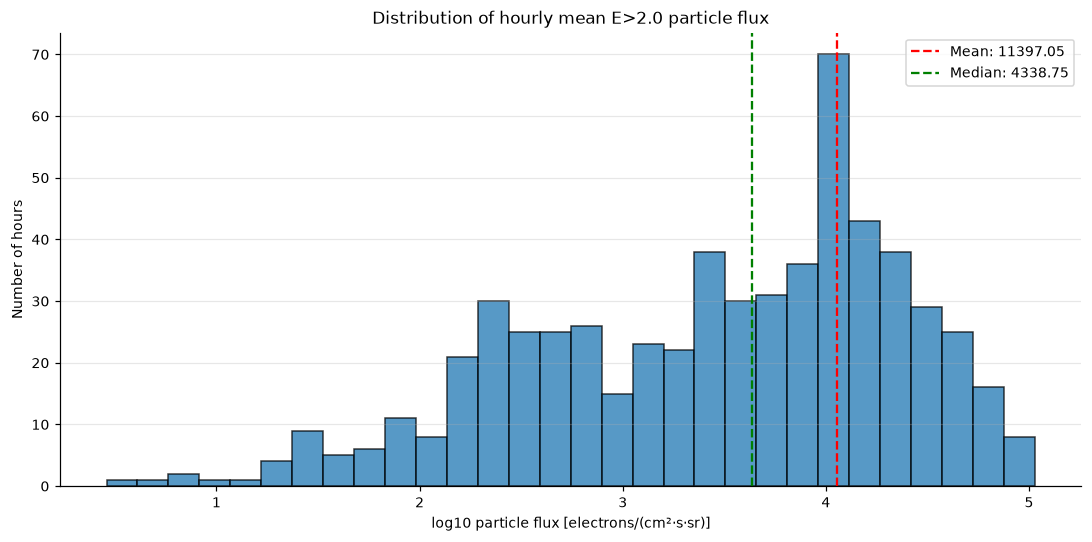

In [21]:
# ВАШ КОД
import numpy as np
import matplotlib.pyplot as plt

flow = M['e_gt_2_0_mean'].dropna()

mean_value = flow.mean()
median_value = flow.median()

print(f'Mean: {mean_value:.2f}')
print(f'Median: {median_value:.2f}')

# Для log10 можна брати лише додатні значення
log_flow = np.log10(flow[flow > 0])

plt.figure(figsize=(10, 5))

plt.hist(
    log_flow,
    bins=30,
    edgecolor='black',
    alpha=0.75
)

plt.axvline(
    np.log10(mean_value),
    color='red',
    linestyle='--',
    label=f'Mean: {mean_value:.2f}'
)

plt.axvline(
    np.log10(median_value),
    color='green',
    linestyle='--',
    label=f'Median: {median_value:.2f}'
)

plt.title('Distribution of hourly mean E>2.0 particle flux')
plt.xlabel('log10 particle flux [electrons/(cm²·s·sr)]')
plt.ylabel('Number of hours')
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

**Висновок:**

Середнє значення потоку становить приблизно 11397, а медіана — 4339,
оскільки розподіл сильно зміщений праворуч: невелика кількість годин із дуже
високим потоком значно збільшує середнє, але слабше впливає на медіану.

### Графік 2. Чи відрізняється швидкість вітру між групами годин?
Побудуйте діаграму розмаху (`boxplot`) швидкості сонячного вітру окремо для кожної
групи з завдання 4.4.

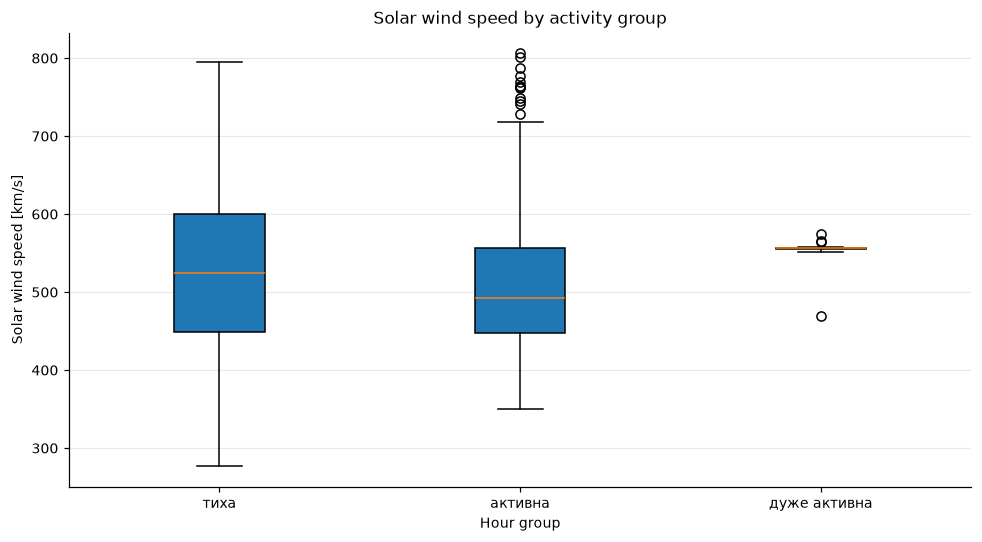

група
тиха            524.0
активна         492.0
дуже активна    556.0
Name: wind_speed, dtype: float64


In [22]:
# ВАШ КОД
import matplotlib.pyplot as plt

group_order = ['тиха', 'активна', 'дуже активна']

plot_data = [
    M.loc[M['група'] == group, 'wind_speed'].dropna()
    for group in group_order
]

plt.figure(figsize=(9, 5))

plt.boxplot(
    plot_data,
    tick_labels=group_order,
    patch_artist=True,
    showfliers=True
)

plt.title('Solar wind speed by activity group')
plt.xlabel('Hour group')
plt.ylabel('Solar wind speed [km/s]')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

# Медіана швидкості в кожній групі
print(
    M.groupby('група', observed=False)['wind_speed']
     .median()
)

**Висновок:**

Швидкість сонячного вітру в групах значною мірою перекривається, але група
«дуже активна» має найбільшу медіану — приблизно 556 км/с, тому чіткого
послідовного зростання швидкості від «тихої» до «дуже активної» групи немає.

### Графік 3. Чи пов'язані змінні вашої пари?
Побудуйте діаграму розсіювання для пари з вашого завдання. Порахуйте коефіцієнт
кореляції між ними.

Correlation coefficient: -0.039


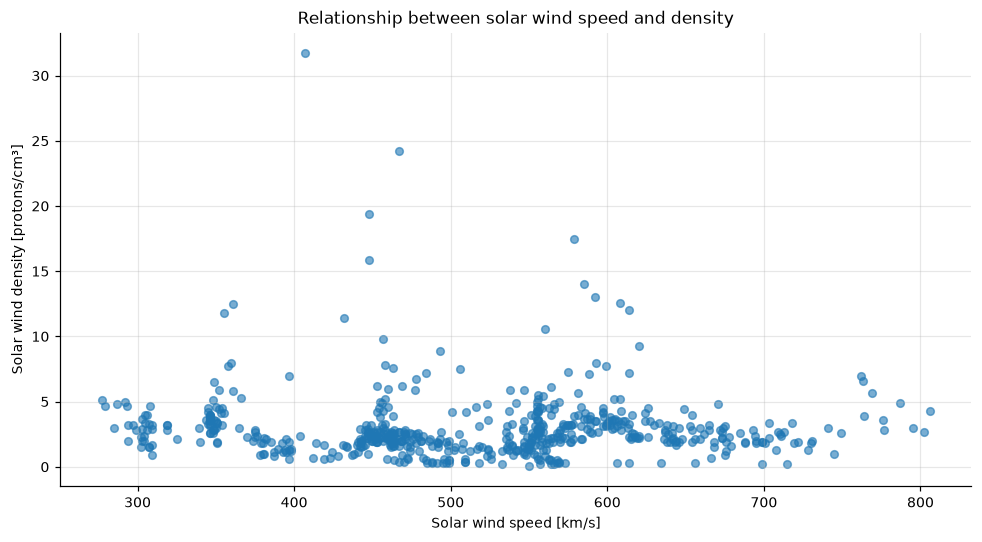

In [23]:
# ВАШ КОД
import matplotlib.pyplot as plt

pair = M[['wind_speed', 'wind_density']].dropna()

correlation = pair['wind_speed'].corr(pair['wind_density'])

print(f'Correlation coefficient: {correlation:.3f}')

plt.figure(figsize=(9, 5))

plt.scatter(
    pair['wind_speed'],
    pair['wind_density'],
    alpha=0.6,
    s=25
)

plt.title('Relationship between solar wind speed and density')
plt.xlabel('Solar wind speed [km/s]')
plt.ylabel('Solar wind density [protons/cm³]')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Висновок:**

Коефіцієнт кореляції дорівнює приблизно −0,039, тому в цих даних практично
немає лінійного зв’язку між швидкістю та густиною сонячного вітру.

### Графік 4. Скільки годин у кожній групі?
Побудуйте стовпчикову діаграму кількості годин за групами. Підпишіть кожен стовпчик
кількістю годин і відсотком від загальної кількості.

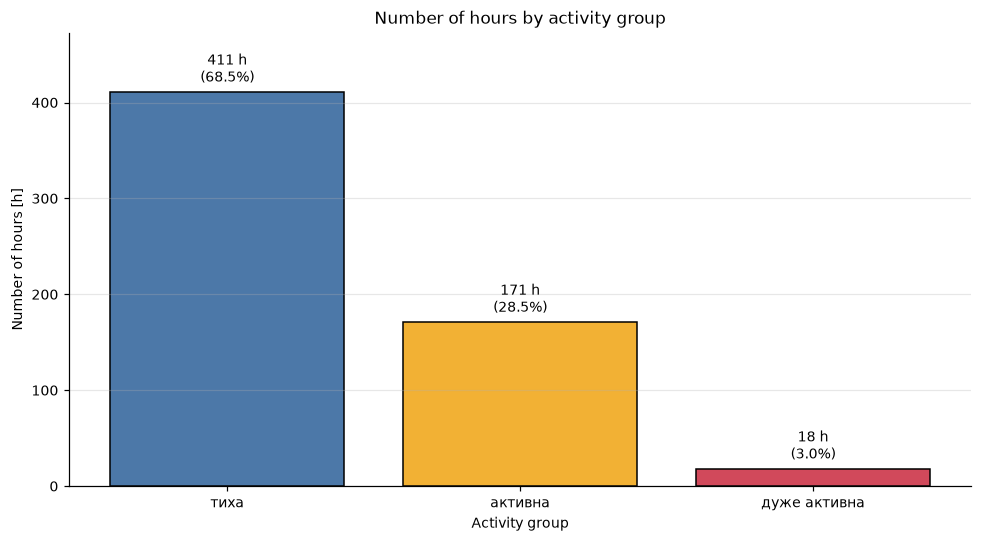

,hours,percentage
група,,
тиха,411,68.5
активна,171,28.5
дуже активна,18,3.0


In [24]:
# ВАШ КОД
import matplotlib.pyplot as plt

group_order = ['тиха', 'активна', 'дуже активна']

counts = (
    M['група']
    .value_counts()
    .reindex(group_order, fill_value=0)
)

total = counts.sum()
percentages = counts / total * 100

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    group_order,
    counts,
    color=['#4C78A8', '#F2B134', '#D1495B'],
    edgecolor='black'
)

# Підписи над стовпчиками
for bar, count, percentage in zip(bars, counts, percentages):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + total * 0.01,
        f'{count} h\n({percentage:.1f}%)',
        ha='center',
        va='bottom'
    )

ax.set_title('Number of hours by activity group')
ax.set_xlabel('Activity group')
ax.set_ylabel('Number of hours [h]')
ax.set_ylim(0, counts.max() * 1.15)
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

display(
    pd.DataFrame({
        'hours': counts,
        'percentage': percentages.round(1)
    })
)

**Висновок:**

Більшість спостережень припадає на «тихі» години — 411 годин (68,5%),
тоді як «дуже активними» були лише 18 годин (3%).

### Графік 5. Як усе це виглядало в часі?
Побудуйте лінійний графік максимуму потоку P>10 за годину за весь період спостережень.

Якщо крива виявиться нечитабельною — згадайте, що допомогло в графіку 1.

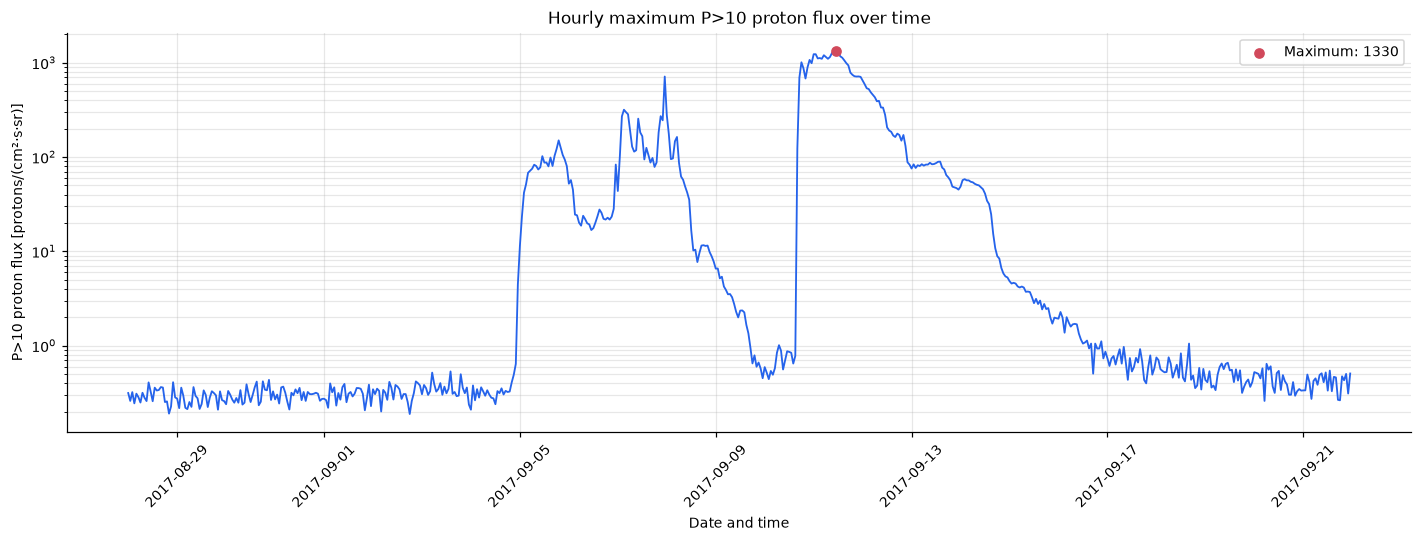

Maximum value: 1330
Peak time: 2017-09-11 11:00:00


In [25]:
# ВАШ КОД
import matplotlib.pyplot as plt

timeline = (
    M[['ts', 'p_gt_10_max']]
    .dropna()
    .query('p_gt_10_max > 0')
    .sort_values('ts')
)

peak_index = timeline['p_gt_10_max'].idxmax()
peak = timeline.loc[peak_index]

fig, ax = plt.subplots(figsize=(13, 5))

ax.plot(
    timeline['ts'],
    timeline['p_gt_10_max'],
    color='#2563EB',
    linewidth=1.2
)

ax.scatter(
    peak['ts'],
    peak['p_gt_10_max'],
    color='#D1495B',
    zorder=3,
    label=f"Maximum: {peak['p_gt_10_max']:.0f}"
)

ax.set_yscale('log')

ax.set_title('Hourly maximum P>10 proton flux over time')
ax.set_xlabel('Date and time')
ax.set_ylabel('P>10 proton flux [protons/(cm²·s·sr)]')
ax.grid(True, which='both', alpha=0.3)
ax.legend()

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print(f"Maximum value: {peak['p_gt_10_max']:.0f}")
print(f"Peak time: {peak['ts']}")

**Висновок:**

Протягом більшої частини періоду потік P>10 залишався низьким, але у вересні
відбулося різке зростання з найбільшим погодинним максимумом 1330
протонів/(см²·с·ср) 11 вересня 2017 року.

---
# Етап 6. Два графіки одних і тих самих даних

Нижче побудовано два графіки. Дані в них **одні й ті самі** — це той самий стовпець
з тієї самої таблиці, жодне число не змінено.

Виконайте клітинку й подивіться на обидва.

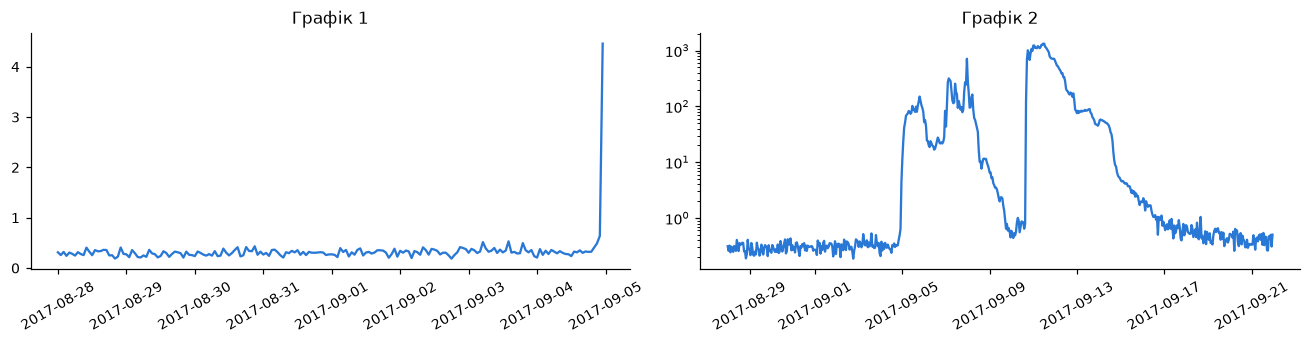

In [26]:
СТОВПЕЦЬ = 'p_gt_10_max'   # <- впишіть назву свого стовпця з МАКСИМУМОМ P>10 за годину

вікно = M[(M['ts'] >= '2017-08-28') & (M['ts'] < '2017-09-05')]

fig, ax = plt.subplots(1, 2, figsize=(12, 3.2))

ax[0].plot(вікно['ts'], вікно[СТОВПЕЦЬ], color='#2a78d6')
ax[0].set_title('Графік 1')
ax[0].tick_params(axis='x', rotation=30)

ax[1].plot(M['ts'], M[СТОВПЕЦЬ], color='#2a78d6')
ax[1].set_yscale('log')
ax[1].set_title('Графік 2')
ax[1].tick_params(axis='x', rotation=30)

fig.tight_layout()
plt.show()

### Завдання 6.1
Дайте відповідь на три питання:

1. Який висновок про космічну погоду у вересні 2017 року зробить людина, яка бачила
   **тільки перший** графік?
2. Який висновок зробить людина, яка бачила **тільки другий**?
3. Чим ці два графіки відрізняються між собою? Назвіть **дві** відмінності —
   вони обидві є в коді вище.

*Жодне число в обох графіках не підроблене. Різниця виникла тільки через те,
як їх побудували.*

**Відповідь 6.1:**

1. Висновок з першого графіка: людина, яка бачила лише перший графік, може зробити висновок, що у вересні
2017 року потік протонів P>10 був переважно низьким і космічна погода була
відносно спокійною.
2. Висновок з другого графіка: людина, яка бачила лише другий графік, побачить, що потік сильно змінювався
і у вересні відбулися різкі сплески сонячної активності, зокрема максимум
1330 протонів/(см²·с·ср) 11 вересня.
3. Дві відмінності між ними: графіки відрізняються двома параметрами:
   - перший показує лише період від 28 серпня до 4 вересня, а другий — весь
     період спостережень;
   - перший використовує лінійну шкалу осі Y, а другий — логарифмічну.


### Завдання 6.2
Уявіть, що вам потрібно **одним графіком** чесно показати, що відбувалося в цьому
періоді. Побудуйте його самі й підпишіть заголовком, який формулює висновок.

Поясніть у клітинці нижче, чому ви обрали саме такий вигляд.

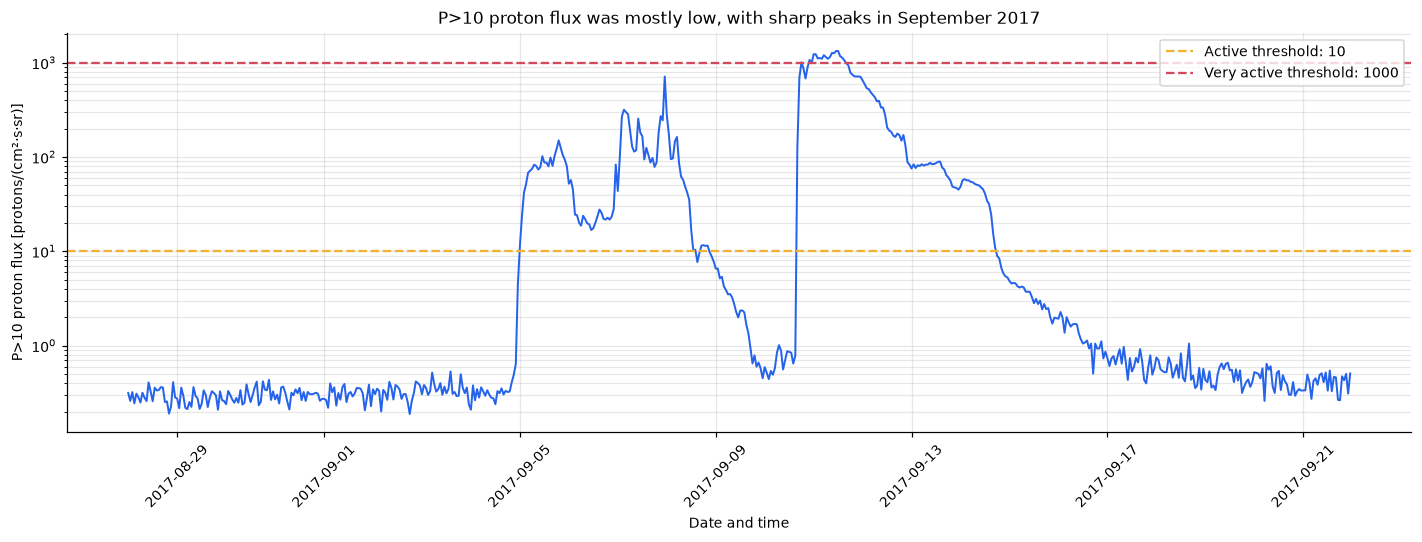

In [27]:
# ВАШ КОД
import matplotlib.pyplot as plt

data = (
    M[['ts', 'p_gt_10_max']]
    .dropna()
    .sort_values('ts')
)

fig, ax = plt.subplots(figsize=(13, 5))

ax.plot(
    data['ts'],
    data['p_gt_10_max'],
    color='#2563EB',
    linewidth=1.3
)

# Межі груп активності
ax.axhline(
    10,
    color='#F2B134',
    linestyle='--',
    label='Active threshold: 10'
)

ax.axhline(
    1000,
    color='#D1495B',
    linestyle='--',
    label='Very active threshold: 1000'
)

ax.set_yscale('log')

ax.set_title(
    'P>10 proton flux was mostly low, with sharp peaks in September 2017'
)
ax.set_xlabel('Date and time')
ax.set_ylabel('P>10 proton flux [protons/(cm²·s·sr)]')
ax.grid(True, which='both', alpha=0.3)
ax.legend()

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


**Відповідь 6.2:** *(чому ви побудували графік саме так)*

Я показав увесь період спостережень, щоб не приховувати
вересневі сплески, та використав логарифмічну шкалу осі Y, оскільки значення
потоку відрізняються на кілька порядків. Додані лінії на рівнях 10 і 1000
показують межі між тихими, активними та дуже активними годинами. Такий графік
одночасно дозволяє побачити звичайний рівень потоку й короткі сильні сплески.

---
# Етап 7. Три спостереження та ваше питання

### Завдання 7.1
Запишіть **три спостереження** про ці дані, які ви зробили під час роботи.

Спостереження — це твердження, яке спирається на конкретне число або графік з вашого
ноутбука. Не «дані цікаві», а, наприклад, «максимальне значення потоку у 2000 разів
більше за медіанне, і всі такі години припадають на одні й ті самі три доби».

Для кожного вкажіть, **де саме** у вашій роботі його видно.

**Спостереження 1:**
 Середнє значення погодинного потоку E>2.0 становить приблизно 11397,
а медіана — 4339, тобто середнє приблизно у 2,6 раза більше через невелику
кількість дуже високих значень. Це видно на графіку 1 та в розрахунках
середнього і медіани під ним.

**Спостереження 2:**
 Між швидкістю та густиною сонячного вітру практично немає лінійного
зв’язку: коефіцієнт кореляції дорівнює приблизно −0,039. Це видно на
діаграмі розсіювання та в розрахунку кореляції для графіка 3.

**Спостереження 3:**
 Більшість годин були «тихими» — 411 годин (68,5%), активними були
171 година (28,5%), а дуже активними — лише 18 годин (3%). Водночас
максимум потоку P>10 досяг 1330 протонів/(см²·с·ср) 11 вересня 2017 року.
Це видно на графіках 4 і 5.

### Завдання 7.2 — ваше індивідуальне питання
Дайте відповідь на додаткове питання зі свого завдання. Відповідь має спиратися
на обчислення: наведіть код і результат, а потім сформулюйте висновок словами.

In [28]:
# ВАШ КОД
numeric_columns = M.select_dtypes(include='number')

means = numeric_columns.mean()
standard_deviations = numeric_columns.std()

coefficient_of_variation = (
    standard_deviations / means.abs()
).sort_values(ascending=False)

result = pd.DataFrame({
    'mean': means,
    'std': standard_deviations,
    'coefficient_of_variation': coefficient_of_variation
}).sort_values(
    'coefficient_of_variation',
    ascending=False
)

display(result)

largest_column = coefficient_of_variation.idxmax()

print('Column with the largest relative spread:', largest_column)
print(
    'Coefficient of variation:',
    coefficient_of_variation[largest_column]
)

,mean,std,coefficient_of_variation
p_gt_100_mean,1.658624,7.145972,4.308375
p_gt_100_max,1.816405,7.671319,4.223354
p_gt_50_mean,7.443857,28.599421,3.842016
p_gt_50_max,7.963117,30.086763,3.778265
p_gt_30_mean,18.831273,67.218736,3.569527
p_gt_30_max,20.147723,70.722633,3.510205
p_gt_10_mean,76.454218,221.848856,2.901722
p_gt_10_max,84.001592,237.466303,2.826926
p_gt_1_max,950.855460,2524.240439,2.654705
p_gt_5_mean,156.589812,387.853354,2.476875


Column with the largest relative spread: p_gt_100_mean
Coefficient of variation: 4.3083745563877445


**Відповідь 7.2:**

Найбільший розкид відносно власного середнього має
стовпець `p_gt_100_mean`. Його середнє становить приблизно 1,659,
стандартне відхилення — 7,146, а коефіцієнт варіації — 4,308, або близько
431%. Це означає, що погодинний середній потік протонів P>100 дуже
нестабільний відносно свого звичайного рівня: більшість значень малі,
але трапляються значно більші сплески.

---
# Етап 8. Декларація про використання інструментів штучного інтелекту

Користуватися мовними моделями під час виконання цієї роботи **дозволено**. Це
нормальна інженерна практика, і курс про штучний інтелект не має підстав її забороняти.

Обов'язковою є прозорість: ви вказуєте, де саме і як скористалися інструментом —
так само, як у науковій статті вказують використане програмне забезпечення.
**Задекларована допомога порушенням не є.**

Порушенням є інше: здати роботу, яку ви не можете пояснити. На захисті вас попросять
показати конкретний рядок вашого коду, пояснити, чому він саме такий, і внести в нього
невелику зміну на місці. Якщо код згенеровано, але ви його розумієте — робота
зарахована. Якщо не розумієте — не зарахована, незалежно від того, хто його написав.

### Завдання 8.1
Заповніть словник. Для кожного етапу оберіть одне з формулювань:

* `'ні'` — інструментами ШІ не користувався;
* `'синтаксис'` — питав про назву функції або синтаксис, код писав сам;
* `'код, перевірено'` — код згенеровано, я його прочитав, перевірив і розумію;
* `'текст, перероблено'` — згенеровано чернетку тексту, яку я переписав по суті;
* `'текст, як є'` — згенерований текст залишено майже без змін.

Останній варіант не заборонений, але прямо впливає на оцінку: бали ставляться
за висновки, а не за наявність абзацу.

In [29]:
ІНСТРУМЕНТИ_ШІ = 'Codex'     # напр. 'ChatGPT' або 'не використовував'

ДЕКЛАРАЦІЯ = {
    'етапи 1–2, читання файлу та розбір таблиць': 'ні',
    'етап 3, паспорт даних і дивні значення':     'синтаксис',
    'етап 4, об’єднання таблиць':                 'код, перевірено',
    'етап 5, побудова графіків':                  'код, перевірено',
    'етап 5, формулювання висновків':             'текст, перероблено',
    'етапи 6–7, порівняння графіків і спостереження': 'код, перевірено',
}

# Що саме ви перевірили за згенерованим кодом чи текстом — конкретно:
# які числа звірили, що переписали, де знайшли помилку.
ЩО_ПЕРЕВІРЕНО = '''
Перевірено розміри таблиць: A — 7200×14, B — 25×4, C — 601×8.
Звірено часові межі: A — 28.08–21.09.2017, B — 28.08–21.09.2017,
C — 28.08–22.09.2017.

У таблиці C знайдено по 8 від’ємних значень швидкості та густини вітру.
Після їх заміни на NaN мінімум швидкості змінився з -1 до 277 км/с,
а густини — з -1 до 0,1 протона/см³.

Перевірено результати графіків: середнє потоку E>2.0 — 11397,05,
медіана — 4338,75; кореляція швидкості й густини вітру — -0,039.
До тихої групи потрапило 411 годин, до активної — 171,
до дуже активної — 18. Максимум P>10 дорівнює 1330 і спостерігався
11.09.2017.

Для індивідуального питання перевірено, що найбільший коефіцієнт варіації
має p_gt_100_mean — 4,308. Також виправлено помилку сумісності Matplotlib:
параметр labels у boxplot замінено на tick_labels.
'''

# True означає: я можу пояснити кожен рядок свого коду, відтворити будь-який
# результат цієї роботи та внести зміни в код на вимогу під час захисту.
ПІДТВЕРДЖУЮ = True

In [30]:
# --- перевірка повноти декларації: клітинку не редагувати --------------------
ДОЗВОЛЕНІ = {'ні', 'синтаксис', 'код, перевірено', 'текст, перероблено', 'текст, як є'}

assert ІНСТРУМЕНТИ_ШІ.strip(), 'Вкажіть інструменти або напишіть «не використовував»'
порожні = [k for k, v in ДЕКЛАРАЦІЯ.items() if not str(v).strip()]
assert not порожні, 'Не заповнено пункти декларації: %s' % '; '.join(порожні)
чужі = {v for v in ДЕКЛАРАЦІЯ.values() if v not in ДОЗВОЛЕНІ}
assert not чужі, 'Недопустимі значення: %s. Оберіть з переліку вище.' % ', '.join(sorted(чужі))
assert len(ЩО_ПЕРЕВІРЕНО.strip()) >= 120, ('Опишіть конкретніше, що саме ви перевірили '
                                           '(зараз %d символів, потрібно щонайменше 120)'
                                           % len(ЩО_ПЕРЕВІРЕНО.strip()))
assert ПІДТВЕРДЖУЮ is True, 'Підтвердьте, що можете пояснити власний код на захисті'

print('ДЕКЛАРАЦІЯ ПРО ВИКОРИСТАННЯ ІНСТРУМЕНТІВ ШІ')
print('=' * 78)
print('%-46s %s' % ('автор:', ПІБ))
print('%-46s %s' % ('інструменти:', ІНСТРУМЕНТИ_ШІ))
print('-' * 78)
for k, v in ДЕКЛАРАЦІЯ.items():
    print('%-46s %s' % (k + ':', v))
print('-' * 78)
print('перевірено автором:')
print(ЩО_ПЕРЕВІРЕНО)
print('=' * 78)
print('Автор підтверджує, що може пояснити кожен рядок коду під час захисту.')

ДЕКЛАРАЦІЯ ПРО ВИКОРИСТАННЯ ІНСТРУМЕНТІВ ШІ
автор:                                         Бубельник Юрій Олегович
інструменти:                                   Codex
------------------------------------------------------------------------------
етапи 1–2, читання файлу та розбір таблиць:    ні
етап 3, паспорт даних і дивні значення:        синтаксис
етап 4, об’єднання таблиць:                    код, перевірено
етап 5, побудова графіків:                     код, перевірено
етап 5, формулювання висновків:                текст, перероблено
етапи 6–7, порівняння графіків і спостереження: код, перевірено
------------------------------------------------------------------------------
перевірено автором:

Перевірено розміри таблиць: A — 7200×14, B — 25×4, C — 601×8.
Звірено часові межі: A — 28.08–21.09.2017, B — 28.08–21.09.2017,
C — 28.08–22.09.2017.

У таблиці C знайдено по 8 від’ємних значень швидкості та густини вітру.
Після їх заміни на NaN мінімум швидкості змінився з -1 до 277 км/с,


---
# Крок 9. Збереження результату та фінальна самоперевірка

Об'єднана таблиця знадобиться вам у лабораторних роботах № 3 і № 4 — збережіть її
й не втрачайте до кінця семестру.

In [31]:
M.to_csv('master_hourly.csv', index=False)
print('збережено:', M.shape)

збережено: (601, 21)


In [32]:
# --- фінальна самоперевірка --------------------------------------------------
перевірки = {
    'ПІБ і варіант заповнено':        bool(ПІБ) and bool(ВАРІАНТ),
    'таблиця A (7200 рядків)':        len(A) == 7200,
    'таблиця B (25 рядків)':          len(B) == 25,
    'таблиця C (601 рядок)':          len(C) == 601,
    'таблиці об’єднано':              M is not None and 590 <= len(M) <= 605,
    'стовпець «група» є':             'група' in M.columns,
    'усі дати у 2017 році':           int(pd.to_datetime(M['ts']).dt.year.min()) == 2017,
    'декларацію заповнено':           bool(ІНСТРУМЕНТИ_ШІ.strip()) and ПІДТВЕРДЖУЮ is True,
}
for k, v in перевірки.items():
    print(('OK   ' if v else 'НЕ ОК') + '  ' + k)

if all(перевірки.values()):
    print('\nТехнічна частина роботи виконана.')
    print('Тепер переконайтеся, що заповнені ВСІ клітинки з відповідями та висновками,')
    print('і виконайте Kernel → Restart & Run All перед здачею.')

OK     ПІБ і варіант заповнено
OK     таблиця A (7200 рядків)
OK     таблиця B (25 рядків)
OK     таблиця C (601 рядок)
OK     таблиці об’єднано
OK     стовпець «група» є
OK     усі дати у 2017 році
OK     декларацію заповнено

Технічна частина роботи виконана.
Тепер переконайтеся, що заповнені ВСІ клітинки з відповідями та висновками,
і виконайте Kernel → Restart & Run All перед здачею.
